In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# scikitlearn


In [2]:
df = pd.read_csv("RealEstate.csv")
df

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.917,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.917,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833,5.0,390.56840,5,24.97937,121.54245,43.1
...,...,...,...,...,...,...,...,...
409,410,2013.000,13.7,4082.01500,0,24.94155,121.50381,15.4
410,411,2012.667,5.6,90.45606,9,24.97433,121.54310,50.0
411,412,2013.250,18.8,390.96960,7,24.97923,121.53986,40.6
412,413,2013.000,8.1,104.81010,5,24.96674,121.54067,52.5


In [3]:
X = df[[
    "X1 transaction date",
    "X2 house age",
    "X3 distance to the nearest MRT station",
    "X4 number of convenience stores",
    "X5 latitude",
    "X6 longitude"
]]
# X
y = df["Y house price of unit area"]

In [4]:
df.head()

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.917,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.917,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833,5.0,390.56840,5,24.97937,121.54245,43.1


In [5]:
df.shape

(414, 8)

In [6]:
df.columns

Index(['No', 'X1 transaction date', 'X2 house age',
       'X3 distance to the nearest MRT station',
       'X4 number of convenience stores', 'X5 latitude', 'X6 longitude',
       'Y house price of unit area'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 414 entries, 0 to 413
Data columns (total 8 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   No                                      414 non-null    int64  
 1   X1 transaction date                     414 non-null    float64
 2   X2 house age                            414 non-null    float64
 3   X3 distance to the nearest MRT station  414 non-null    float64
 4   X4 number of convenience stores         414 non-null    int64  
 5   X5 latitude                             414 non-null    float64
 6   X6 longitude                            414 non-null    float64
 7   Y house price of unit area              414 non-null    float64
dtypes: float64(6), int64(2)
memory usage: 26.0 KB


In [8]:
df.describe()

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
count,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000
mean,207.500000,2013.148971,17.712560,1083.885689,4.094203,24.969030,121.533361,37.980193
std,119.655756,0.281967,11.392485,1262.109595,2.945562,0.012410,0.015347,13.606488
min,1.000000,2012.667000,0.000000,23.382840,0.000000,24.932070,121.473530,7.600000
25%,104.250000,2012.917000,9.025000,289.324800,1.000000,24.963000,121.528085,27.700000
50%,207.500000,2013.167000,16.100000,492.231300,4.000000,24.971100,121.538630,38.450000
75%,310.750000,2013.417000,28.150000,1454.279000,6.000000,24.977455,121.543305,46.600000
max,414.000000,2013.583000,43.800000,6488.021000,10.000000,25.014590,121.566270,117.500000


In [9]:
le = LabelEncoder()

for col in df.select_dtypes(include='object').columns:
    df[col] = le.fit_transform(df[col])


In [10]:
X = df.iloc[:, :-1]
y = df.iloc[:, -1]


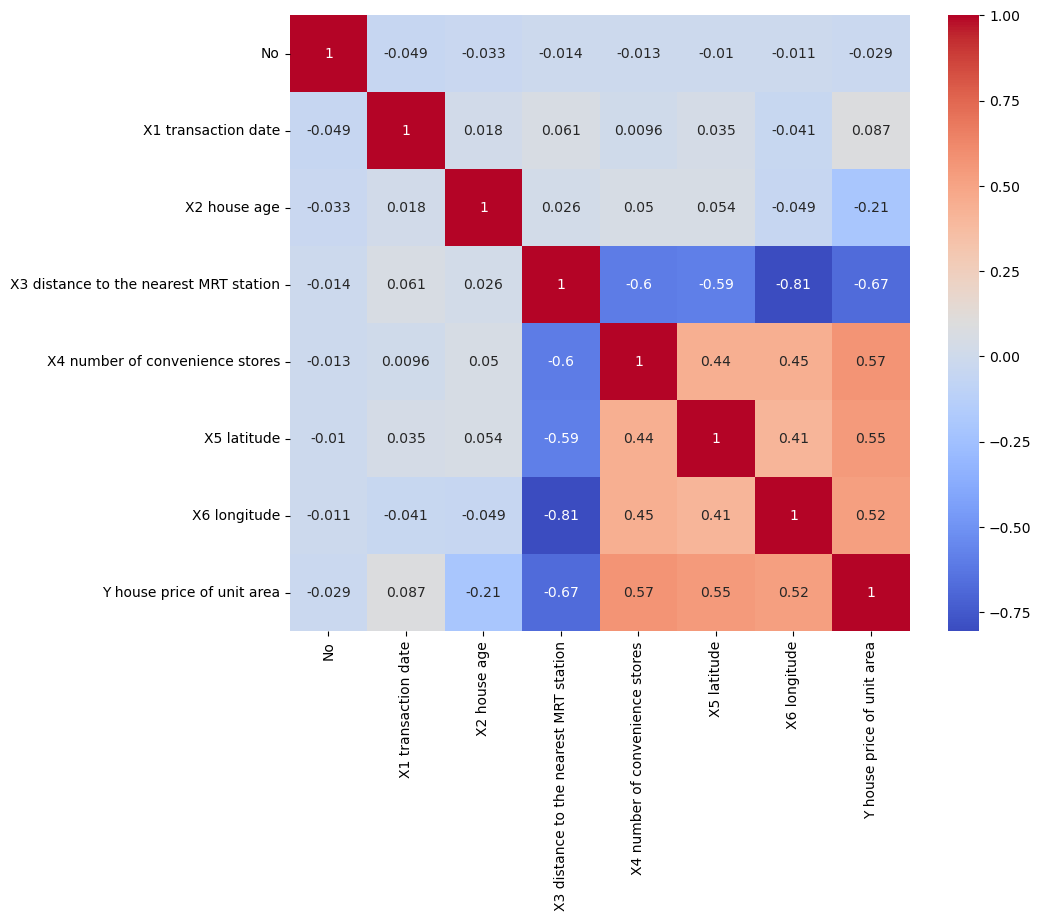

In [11]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.show()

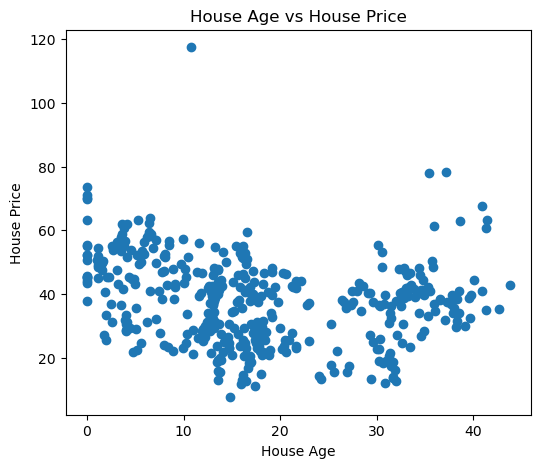

In [12]:

plt.figure(figsize=(6,5))
plt.scatter(df["X2 house age"], df["Y house price of unit area"])
plt.title("House Age vs House Price")
plt.xlabel("House Age")
plt.ylabel("House Price")
plt.show()

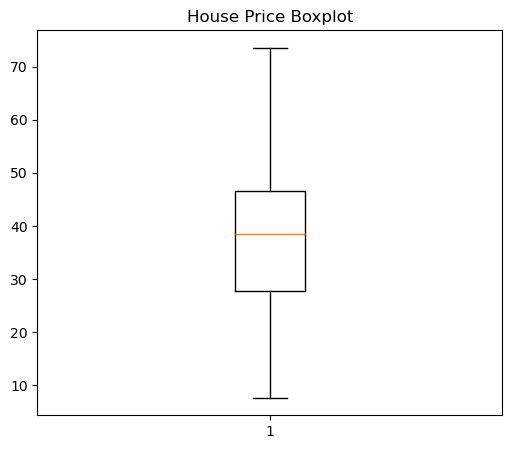

In [13]:
plt.figure(figsize=(6,5))

plt.boxplot(
    df["Y house price of unit area"],
    showfliers=False   # Outlier dots remove
)

plt.title("House Price Boxplot")
plt.show()


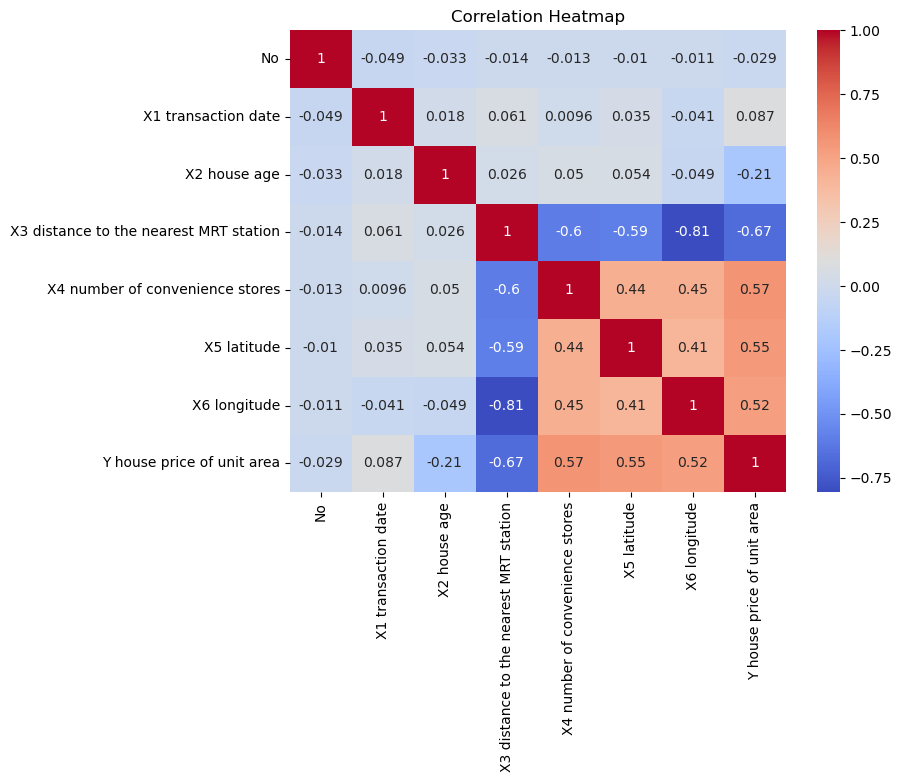

In [14]:

plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()


In [15]:
from sklearn.model_selection import train_test_split

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [17]:
from sklearn.linear_model import LinearRegression

In [18]:
model = LinearRegression()
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [19]:
y_pred = model.predict(X_test)
y_pred

array([47.04645871, 40.40783016, 43.37463978, 39.20600382, 26.62817953,
       45.8923956 , 44.33888897, 46.74448468, 24.43235155, 55.06258487,
       34.60848974, 36.92386329, 36.76420984, 24.30494918, 35.79519845,
       33.44810036, 44.24993318, 44.98654734, 29.18096544, 44.80711275,
        1.15259949, 36.10694406, 47.26486776, 45.90792727, 10.96198835,
       38.69069634, 12.57701679, 43.61237869, 35.7142565 , 37.55475044,
       14.14012034, 40.46209983, 35.90891223, 28.5174525 , 47.38286733,
       30.9022379 , 50.43545093, 12.92669013, 48.95222574, 39.27068588,
       39.3872837 , 40.09381011, 48.20107097, 37.08010208, 39.54765933,
       47.348201  , 43.3815801 , 21.07747224, 47.05299802, 44.57951775,
       48.24233055, 48.12297596, 41.42189435, 42.25141469, 36.32214409,
       15.69024514, 37.64733588, 35.12221291, 29.08561558, 46.86297981,
       32.07763941, 33.25961566, 15.22965501,  9.01697131,  9.37929873,
       33.78712833, 29.59931587, 47.50139803, 33.81312917, 31.84

In [20]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("\nMAE =", mae)
print("MSE =", mse)
print("RMSE =", rmse)
print("R2 Score =", r2)


MAE = 5.418035098629085
MSE = 54.601960673378365
RMSE = 7.389313951469267
R2 Score = 0.6745228670350798


In [21]:
result = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

print(result.head(20))

     Actual  Predicted
358    45.1  47.046459
350    42.3  40.407830
373    52.2  43.374640
399    37.3  39.206004
369    22.8  26.628180
72     36.3  45.892396
262    53.0  44.338889
140    51.4  46.744485
93     16.1  24.432352
70     59.0  55.062585
118    30.6  34.608490
131    30.7  36.923863
336    35.6  36.764210
55     13.7  24.304949
126    62.9  35.795198
376    30.5  33.448100
56     41.9  44.249933
291    54.4  44.986547
365    29.5  29.180965
84     43.7  44.807113


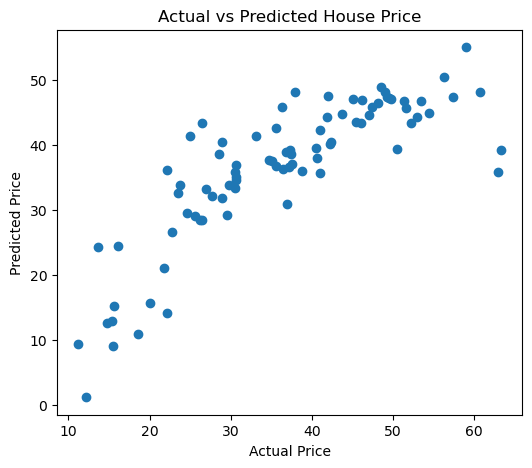

In [22]:
plt.figure(figsize=(6,5))
plt.scatter(y_test, y_pred)

plt.xlabel("Actual Price")

plt.ylabel("Predicted Price")

plt.title("Actual vs Predicted House Price")

plt.show()

In [23]:
print(X_train.columns)

Index(['No', 'X1 transaction date', 'X2 house age',
       'X3 distance to the nearest MRT station',
       'X4 number of convenience stores', 'X5 latitude', 'X6 longitude'],
      dtype='object')


In [24]:
print(sample.columns)

NameError: name 'sample' is not defined

In [ ]:
print(X_train.shape)

In [ ]:
print(df.columns)

In [ ]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2)
for degree in range(1, 11):

    poly = PolynomialFeatures(degree=degree)

    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    model = LinearRegression()
    model.fit(X_train_poly, y_train)

    y_pred = model.predict(X_test_poly)

    score = r2_score(y_test, y_pred)

    print(f"Degree {degree} --> R2 Score = {score:.4f}")


   
    y_pred = best_model.predict(X_test_best)

In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train_poly, y_train)

In [ ]:
print("\n===== Enter House Details =====")

no = int(input("Enter No: "))
date = float(input("Enter Transaction Date: "))
age = float(input("Enter House Age: "))
distance = float(input("Enter Distance to MRT Station: "))
stores = int(input("Enter Number of Convenience Stores: "))
latitude = float(input("Enter Latitude: "))
longitude = float(input("Enter Longitude: "))

sample = pd.DataFrame({
    "No":[no],
    "X1 transaction date":[date],
    "X2 house age":[age],
    "X3 distance to the nearest MRT station":[distance],
    "X4 number of convenience stores":[stores],
    "X5 latitude":[latitude],
    "X6 longitude":[longitude]
})

sample_poly = poly.transform(sample)

prediction = model.predict(sample_poly)

print("\nPredicted House Price =", prediction[0])


===== Enter House Details =====


In [325]:
y_pred = model.predict(X_test_poly)
y_pred

array([ 5.31400977e+01,  3.67318946e+01,  6.05411520e+01,  4.42251209e+01,
        1.80683298e+01,  3.57792571e+01,  4.75270037e+01,  4.98765998e+01,
        2.76930819e+01,  6.38123215e+01,  7.86133404e+00,  3.10604914e+01,
        3.00705398e+01,  3.78162172e+01,  4.22011576e+01,  2.49122035e+01,
        3.55009605e+01,  4.65715448e+01,  2.20317175e+01,  3.67757694e+01,
       -5.40874079e+05,  2.03934983e+01,  5.01239405e+01,  4.22537019e+01,
       -2.44832588e+01,  4.43850227e+01,  9.82060393e-01,  5.36169107e+01,
        4.38900748e+01,  3.75818296e+01,  8.67401940e+02,  2.79714359e+01,
        2.24039286e+01,  2.31814142e+01,  4.73121821e+01,  3.56178636e+01,
        5.17945722e+01, -5.12729149e+02,  4.52817205e+01,  4.45577044e+01,
        5.73799434e+01,  4.19845891e+01,  3.35784467e+01,  3.80142054e+01,
        3.58681151e+01,  4.68864966e+01,  3.82588755e+01, -1.19103563e+02,
        5.08198728e+01,  4.41643311e+01,  5.42627369e+01,  5.17141294e+01,
        4.52801667e+01,  

In [326]:
print("MAE :", mean_absolute_error(y_test, y_pred))
print("MSE :", mean_squared_error(y_test, y_pred))
print("RMSE :", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score :", r2_score(y_test, y_pred))

MAE : 24904.77348791914
MSE : 31489245975.85049
RMSE : 177452.0948759143
R2 Score : -187704421.57111052


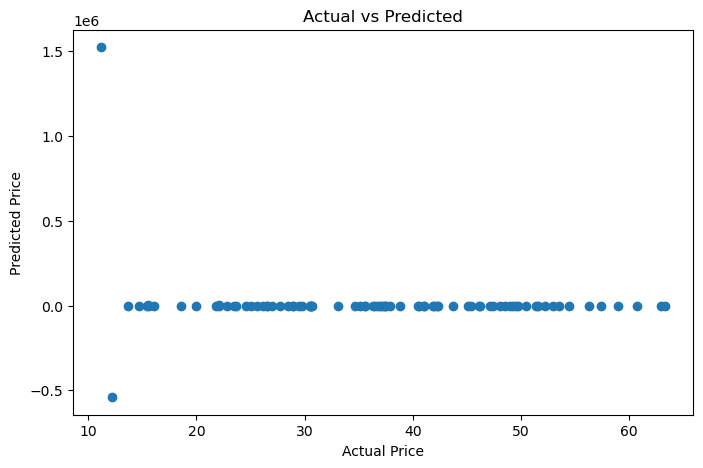

In [327]:
plt.figure(figsize=(8,5))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted")
plt.show()